<a href="https://colab.research.google.com/github/Jimber120/DA-Project-Member-3/blob/main/work/notebooks/01_problem_framing_and_data_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 — Problem Framing, Hypotheses & Data Ingestion: Ranking Signal Analysis

**Project:** FlyRank Ranking Signal Analysis — Predicting Continuous Search Visibility  
**Pipeline Stage:** Notebook 01 of 03 (Problem Framing, Hypotheses & Feature Vector Assembly)  
**Target Variable:** Continuous Search Visibility $\log(1 + \text{impressions\_90d})$ on Held-Out Enterprise Client Portfolios  
**Standardized Split:** Grouped Holdout (`GroupShuffleSplit`, `test_size=0.20`, `random_state=42`) with Zero Client Domain Overlap  

---

### Notebook Architecture & Objectives
This notebook is your starting template for the data audit and feature engineering phase:
1. **Problem Framing & Operational Decision:** Define the operational content refresh decision, continuous search visibility target, and asymmetric error trade-offs.
2. **Core SEO Hypotheses:** Formulate and statistically test 4 core search hypotheses with explicit empirical verdicts (`CONFIRMED`, `MIXED`, `FALSE`, `OPPOSITE`).
3. **Data Ingestion & Scope Audit:** Verify atomic entity grain (`content_id`), document scope limitations, missingness patterns, and rate scaling.
4. **Feature Vector Assembly & Leakage Defense:** Implement SERP inverse power-law ranking signals, engagement ratios, missingness indicators, log-stabilizing transforms, enforce strict leakage blacklists, and export the validated feature dataset.

## 1. Problem Framing & Operational Decision

### 1.1 The Operational Decision
* **What operational decision does this model improve?**  
  Enterprise content and SEO teams manage portfolios spanning thousands of URLs across diverse client domains. Currently, content refresh prioritization relies on crude, lagging manual heuristics (e.g., sorting by calendar age or raw pageviews). This model predicts expected **search visibility** (the latent search impression capacity of a page based on its structural, semantic, and engagement signals). Content strategists and engineering teams act on this model to identify:
  1. **Under-indexed high-potential pages:** Content whose observed features warrant high search impressions but currently lag behind their predicted potential (prime refresh/optimization candidates).
  2. **Over-resourced low-potential pages:** Thin or poorly positioned content that should not consume scarce editorial rewrite hours.

* **Who acts on it?**  
  Content operations leads, technical SEO specialists, and client account managers.

### 1.2 Target Definition: Search Visibility
* **Why Continuous Regression instead of Binary Classification?**  
  Binary classification collapses search performance into an arbitrary threshold (e.g., "declining" vs. "stable"), obscuring orders of magnitude of search impact. Continuous regression models the true scale of visibility across the entire distribution.
* **Target Formulation:**
  $$\text{target\_log\_impressions} = \log(1 + \text{impressions\_90d})$$
  Raw search impressions follow an extreme power-law distribution spanning from single digits to hundreds of thousands. The $\log(1+x)$ transformation compresses extreme right-tail skewness into a well-behaved, symmetric distribution suitable for regression estimators.

### 1.3 Asymmetric Cost of Errors
* **Overestimation Error (False High Visibility):** The model predicts high visibility for low-yield content.  
  *Operational Cost:* Editorial teams waste expensive subject-matter expert hours rewriting, optimizing, and re-indexing pages that fail to generate organic traffic. Opportunity cost is high.
* **Underestimation Error (False Low Visibility):** The model predicts low visibility for high-yield content.  
  *Operational Cost:* The team neglects high-leverage assets, risking rank decay against aggressive competitor content.

## 2. Core SEO Hypotheses

Before building machine learning models, formulate four operational hypotheses based on prevailing SEO heuristics to test whether real-world data supports common industry beliefs:
1. **Hypothesis 1 (Content Depth):** *Article length (`word_count`) exhibits a strong positive relationship with search visibility.*
2. **Hypothesis 2 (Search Demand):** *Target keyword search volume (`search_volume`) strongly determines realized page impressions.*
3. **Hypothesis 3 (SERP Positioning):** *Average SERP rank position (`avg_position`) is inversely correlated with impressions (lower numerical rank = higher visibility).*
4. **Hypothesis 4 (Content Freshness):** *Recently updated content (`days_since_last_update` lower) commands higher search visibility than aged content.*

Each hypothesis should be evaluated using Spearman rank correlation ($\rho$), Pearson correlation ($r$), and visual distribution inspections, concluding with an explicit statistical verdict (`CONFIRMED`, `OPPOSITE`, `MIXED`, or `FALSE`).

In [17]:
# Code Cell 1: Setup, Imports, and Data Ingestion (self-contained: downloads from GitHub, no Drive mount)
import os
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

# ---- Paths (local Colab session storage only) ----
GITHUB_USER = "Jimber120"
GITHUB_REPO = "DA-Project-Member-3"
DATA_FILE = "content_refresh_anonymized.csv"
RAW_PATH = os.path.join("data", "raw", DATA_FILE)
OUT_DIR = os.path.join("work", "outputs")

# If the CSV lives somewhere unusual in the repo, paste its full raw.githubusercontent.com URL here:
DATA_URL_OVERRIDE = None

os.makedirs(os.path.dirname(RAW_PATH), exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)


def _looks_like_csv(path):
    """True if the file is a real CSV (not an HTML error page or a git-lfs pointer)."""
    try:
        with open(path, "r", encoding="utf-8", errors="ignore") as fh:
            header = fh.readline()
        return "content_id" in header and "," in header
    except OSError:
        return False


def download_dataset():
    base = f"https://raw.githubusercontent.com/{GITHUB_USER}/{GITHUB_REPO}"
    candidates = [DATA_URL_OVERRIDE] if DATA_URL_OVERRIDE else []
    for branch in ("main", "master"):
        for sub in ("data/raw/", "data/", "", "work/data/raw/"):
            candidates.append(f"{base}/{branch}/{sub}{DATA_FILE}")
    for url in candidates:
        try:
            urllib.request.urlretrieve(url, RAW_PATH)
        except Exception:
            continue
        if _looks_like_csv(RAW_PATH):
            print(f"Downloaded dataset from: {url}")
            return url
        os.remove(RAW_PATH)
    raise FileNotFoundError(
        "Could not download the dataset from GitHub. Check that the repository is public and set "
        "DATA_URL_OVERRIDE to the exact raw.githubusercontent.com URL of content_refresh_anonymized.csv."
    )


if os.path.exists(RAW_PATH) and _looks_like_csv(RAW_PATH):
    print(f"Found local dataset at {RAW_PATH}; skipping download.")
else:
    download_dataset()

df_raw = pd.read_csv(RAW_PATH)
df = df_raw.copy()

# ---- Data contract checks ----
assert df["content_id"].nunique() == len(df), "Primary key content_id is not unique!"
assert df["client_id"].nunique() == 32, "Expected exactly 32 clients!"

# ---- Continuous regression target ----
df["target_log_impressions"] = np.log1p(df["impressions_90d"])

print(f"Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Clients: {df['client_id'].nunique()}")
print("\nTarget summary: target_log_impressions = log(1 + impressions_90d)")
display(df["target_log_impressions"].describe().to_frame().T)

Found local dataset at data/raw/content_refresh_anonymized.csv; skipping download.
Shape: 30,000 rows x 44 columns
Clients: 32

Target summary: target_log_impressions = log(1 + impressions_90d)


,count,mean,std,min,25%,50%,75%,max
target_log_impressions,30000.0,6.188688,2.688539,0.693147,4.406719,6.595781,8.193193,13.157182


## 3. Data Ingestion: Scope & Limitations

### 3.1 Scope of the Dataset
* **Dataset File:** `data/raw/content_refresh_anonymized.csv` (30,000 rows × 44 columns).
* **Entity Grain:** Exactly 1 row per unique pseudonymized content item (`content_id`).
* **Client Representation:** Exactly 32 distinct pseudonymized enterprise client domains (`client_id`).
* **Observation Window:** A fixed trailing 90-day observation window ending at export time, with 30-day comparative windows (`*_last_30d` vs `*_prev_30d`).
* **Cohort Age:** Established, mature content only (`content_age_days >= 90`). Every row has at least 1 impression (`impressions_90d >= 1`).

### 3.2 Key Data Gotchas & Limitations
1. **Rate Scaling (×100):** Columns `ctr`, `engagement_rate`, `scroll_rate`, `ai_traffic_pct`, and `trend_pct` are recorded as ×100 percentages (`0.76` means `0.76%`, not `76%`).
2. **`avg_position = 0` Unranked State:** 1,205 rows have `avg_position = 0`, denoting unranked status / no impression position recorded, not rank zero.
3. **Systematic Missingness:** Keyword context is missing along `content_type` lines (e.g. `feedly article` rows have no keyword data; ~25.7% of rows lack `word_count`). Blind `fillna(0)` injects artificial category signals; missingness indicators are required.
4. **Observable Telemetry Only:** Internal product decision flags (`health_score`, `priority_score`, `action_type`) are deliberately excluded to prevent circular result leakage.

In [18]:
# Code Cell 2: Completeness and Missingness Audit
n = len(df_raw)

missing = df_raw.isna().sum()
audit = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": (missing / n * 100).round(2),
})

numeric_cols = df_raw.select_dtypes(include=[np.number]).columns
audit["zero_count"] = (df_raw[numeric_cols] == 0).sum().reindex(audit.index)
audit["zero_pct"] = (audit["zero_count"] / n * 100).round(2)

print("=== Columns with missing data ===")
display(audit[audit["missing_count"] > 0].sort_values("missing_pct", ascending=False))

print("\n=== Numeric columns with many exact zeros (top 15) ===")
display(audit.dropna(subset=["zero_count"]).sort_values("zero_pct", ascending=False).head(15)[["zero_count", "zero_pct"]])

# ---- Scope audit ----
print("\n=== Scope limitations ===")
if "content_age_days" in df_raw:
    print(f"Min content_age_days : {df_raw['content_age_days'].min():,.0f}  (mature content only, expected >= 90)")
print(f"Min impressions_90d  : {df_raw['impressions_90d'].min():,.0f}  (active pages only, expected >= 1)")
if "avg_position" in df_raw:
    print(f"avg_position == 0    : {(df_raw['avg_position'] == 0).sum():,} rows (UNRANKED state, not 'rank zero')")
if "search_volume" in df_raw:
    print(f"search_volume == 0   : {(df_raw['search_volume'] == 0).sum():,} rows (untracked / long-tail keywords)")
if "content_type" in df_raw and "word_count" in df_raw:
    print("\nword_count missingness by content_type (systematic, not random):")
    display(df_raw.groupby("content_type")["word_count"].apply(lambda s: s.isna().mean() * 100).round(1).to_frame("word_count_missing_pct"))
for col in ("bounce_rate", "conversion_rate"):
    if col in df_raw:
        print(f"{col}: {df_raw[col].isna().mean() * 100:.1f}% missing -> no tracked sessions (NOT an average value); keep an explicit indicator")

=== Columns with missing data ===


,missing_count,missing_pct,zero_count,zero_pct
provider_used,21438,71.46,NaN,NaN
word_count_tier,7699,25.66,NaN,NaN
char_count,7699,25.66,0.0,0.00
word_count,7699,25.66,0.0,0.00
char_count_tier,7699,25.66,NaN,NaN
model_used,5733,19.11,NaN,NaN
trend_pct,3388,11.29,443.0,1.48
competition_level,2610,8.70,NaN,NaN
search_volume,2468,8.23,11081.0,36.94
competition,2468,8.23,16379.0,54.60



=== Numeric columns with many exact zeros (top 15) ===


,zero_count,zero_pct
ai_sessions_90d,28070.0,93.57
ai_traffic_pct,28070.0,93.57
engagement_rate,21629.0,72.10
engaged_sessions_90d,21629.0,72.10
cpc,20679.0,68.93
clicks_last_30d,18365.0,61.22
clicks_prev_30d,18241.0,60.80
competition,16379.0,54.60
ctr,13212.0,44.04
clicks_90d,13204.0,44.01



=== Scope limitations ===
Min content_age_days : 90  (mature content only, expected >= 90)
Min impressions_90d  : 1  (active pages only, expected >= 1)
avg_position == 0    : 1,205 rows (UNRANKED state, not 'rank zero')
search_volume == 0   : 11,081 rows (untracked / long-tail keywords)

word_count missingness by content_type (systematic, not random):


,word_count_missing_pct
content_type,
comparison article,0.0
feedly article,0.0
keyword article,28.3


=== Hypothesis verdict summary ===


,Hypothesis,Variable,n,Spearman rho,p (rho),Pearson r,p (r),Verdict
0,H1 Content Depth,word_count,22301,0.2986,0.00e+00,0.3366,0.00e+00,CONFIRMED
1,H2 Search Demand,search_volume,27532,-0.0291,1.40e-06,0.0043,4.74e-01,MIXED
2,H3 SERP Positioning,avg_position,28795,-0.0465,3.10e-15,-0.0674,2.18e-30,FALSE
3,H4 Content Freshness,days_since_last_update,30000,0.2542,0.00e+00,0.2109,1.11e-298,OPPOSITE


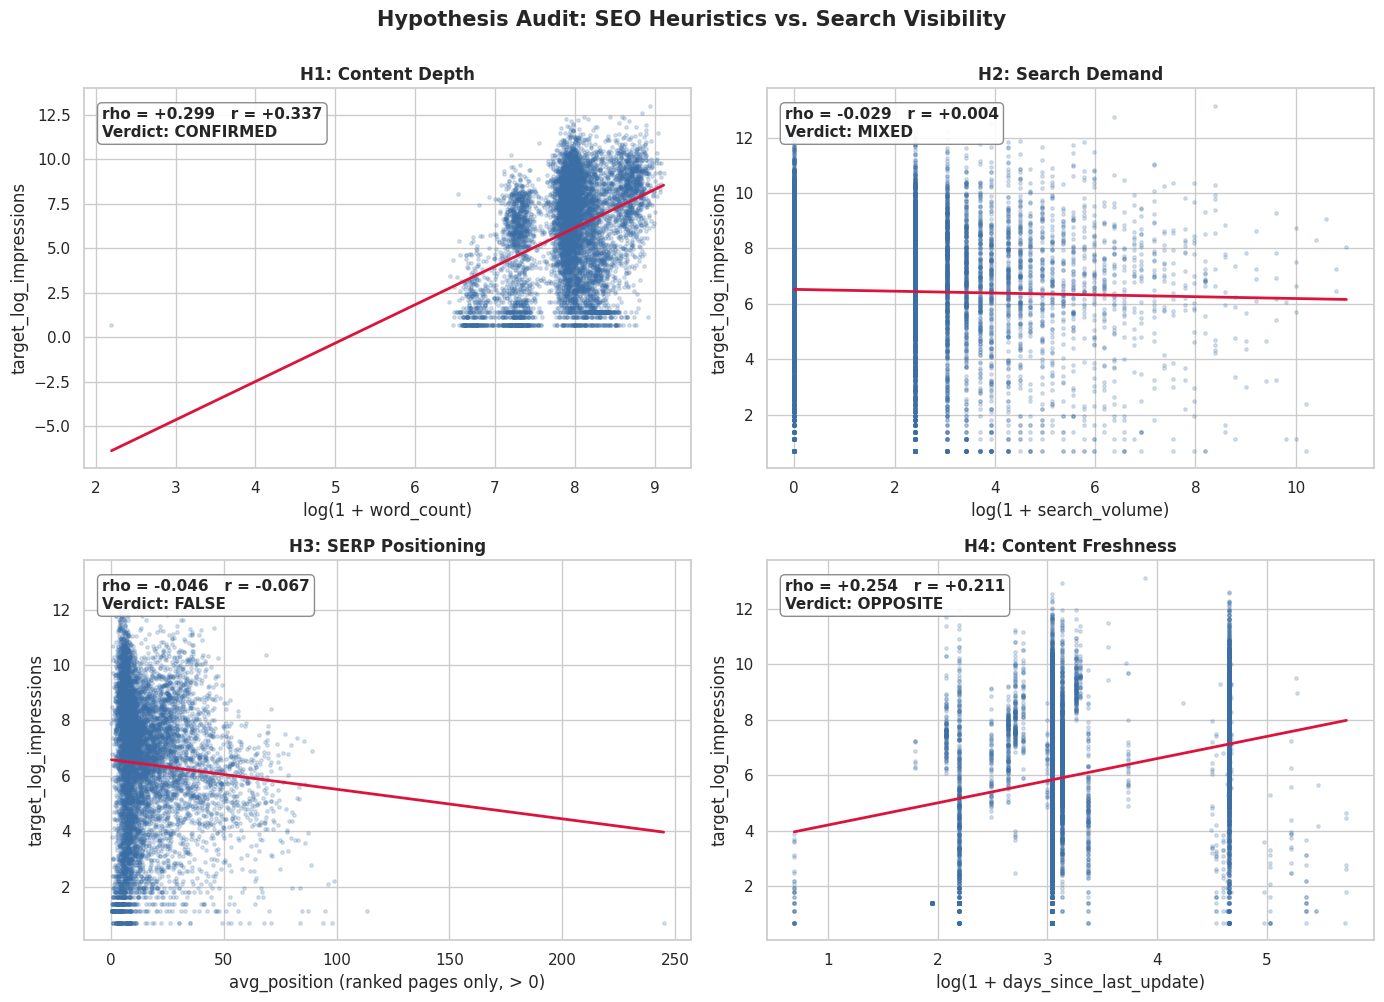

Saved work/outputs/hypothesis_audit_distributions.png


In [19]:
# Code Cell 3: Statistical Hypothesis Testing with Explicit Verdicts
y = df["target_log_impressions"]

HYPOTHESES = [
    dict(id="H1", name="Content Depth",   col="word_count",             expected=+1, plot_x=np.log1p, xlabel="log(1 + word_count)"),
    dict(id="H2", name="Search Demand",   col="search_volume",          expected=+1, plot_x=np.log1p, xlabel="log(1 + search_volume)"),
    dict(id="H3", name="SERP Positioning", col="avg_position",          expected=-1, plot_x=None,     xlabel="avg_position (ranked pages only, > 0)"),
    dict(id="H4", name="Content Freshness", col="days_since_last_update", expected=-1, plot_x=np.log1p, xlabel="log(1 + days_since_last_update)"),
]


def assign_verdict(rho, r, expected_sign):
    """Verdict derived purely from this dataset's correlations (the hypotheses are tested, not assumed).
    MIXED     : Spearman and Pearson disagree in sign, or the effect is weak (0.10 <= |rho| < 0.20)
    FALSE     : negligible effect (|rho| < 0.10)
    CONFIRMED : |rho| >= 0.20 in the direction the SEO belief predicts
    OPPOSITE  : |rho| >= 0.20 in the reverse direction
    """
    if np.sign(rho) != np.sign(r):
        return "MIXED"
    if abs(rho) < 0.10:
        return "FALSE"
    if abs(rho) < 0.20:
        return "MIXED"
    return "CONFIRMED" if np.sign(rho) == expected_sign else "OPPOSITE"


rows, subsets = [], {}
for h in HYPOTHESES:
    sub = df[[h["col"], "target_log_impressions"]].dropna()
    if h["id"] == "H3":
        sub = sub[sub[h["col"]] > 0]          # unranked (0) rows are excluded from the rank test
    rho, p_rho = stats.spearmanr(sub[h["col"]], sub["target_log_impressions"])
    r, p_r = stats.pearsonr(sub[h["col"]], sub["target_log_impressions"])
    v = assign_verdict(rho, r, h["expected"])
    subsets[h["id"]] = sub
    rows.append({
        "Hypothesis": f"{h['id']} {h['name']}", "Variable": h["col"], "n": len(sub),
        "Spearman rho": round(rho, 4), "p (rho)": f"{p_rho:.2e}",
        "Pearson r": round(r, 4), "p (r)": f"{p_r:.2e}",
        "Verdict": v,
    })

verdicts = pd.DataFrame(rows)
print("=== Hypothesis verdict summary ===")
display(verdicts)

# ---- 2x2 audit grid ----
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, h, row in zip(axes.ravel(), HYPOTHESES, rows):
    sub = subsets[h["id"]]
    if len(sub) > 8000:
        sub = sub.sample(8000, random_state=42)
    x = sub[h["col"]] if h["plot_x"] is None else h["plot_x"](sub[h["col"]].clip(lower=0))
    ax.scatter(x, sub["target_log_impressions"], s=6, alpha=0.2, color="#3b6ea5")
    if len(sub) > 2:
        slope, intercept = np.polyfit(x, sub["target_log_impressions"], 1)
        xs = np.linspace(x.min(), x.max(), 50)
        ax.plot(xs, slope * xs + intercept, color="crimson", lw=2)
    ax.set_xlabel(h["xlabel"])
    ax.set_ylabel("target_log_impressions")
    ax.set_title(f"{h['id']}: {h['name']}", fontweight="bold")
    ax.text(0.03, 0.95, f"rho = {row['Spearman rho']:+.3f}   r = {row['Pearson r']:+.3f}\nVerdict: {row['Verdict']}",
            transform=ax.transAxes, va="top", fontsize=11, fontweight="bold",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.9, edgecolor="gray"))
plt.suptitle("Hypothesis Audit: SEO Heuristics vs. Search Visibility", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "hypothesis_audit_distributions.png"), dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {os.path.join(OUT_DIR, 'hypothesis_audit_distributions.png')}")

### Interpretation of Hypotheses Findings
* **Guide for your write-up:**
  * Explain in plain words what each statistical verdict revealed about search traffic.
  * Why did H2 (search volume) show a mixed/weak correlation? (Broad head-terms face high competition).
  * Why was H3 (rank position) false when tested in isolation? (Position without search demand yields zero views).
  * Why did H4 (content freshness) show an opposite result? (Cumulative domain authority and backlink history outweigh recent date updates).

## 4. Feature Vector Assembly & Leakage Defense

### 4.1 Strict Leakage Blacklists
To ensure 100% scientific integrity, the feature pipeline strictly blacklists all leakers:
* **Pseudonymous Identifiers:** `content_id`, `client_id` (used solely for grouping and validation assertions).
* **Direct Target Telemetry:** `impressions_90d`, `clicks_90d`, `ctr` (since CTR contains impressions in its denominator).
* **Outcome Window Metrics:** `impressions_last_30d`, `clicks_last_30d`, `sessions_last_30d`, `impressions_prev_30d`, `clicks_prev_30d`, `sessions_prev_30d`.
* **Target-Derived Labels:** `trend_direction`, `trend_pct`, `impression_tier`.

### 4.2 Domain-Specific Feature Engineering
Engineer high-leverage structural and behavioral signals:
1. **SERP Power-Law Inverse Rank (`serp_rank_power`):**
   $$\text{serp\_rank\_power} = \begin{cases} \frac{1}{\text{avg\_position}}, & \text{if } \text{avg\_position} > 0 \\ 0, & \text{otherwise} \end{cases}$$
2. **Rank Presence Indicator:** `has_rank_data = (avg_position > 0).astype(int)`.
3. **Rank Imputation:** `imputed_avg_position = np.where(avg_position > 0, avg_position, 100.0)`.
4. **Behavioral Ratios:**
   * `engaged_session_ratio = engaged_sessions_90d / (sessions_90d + 1)`
   * `scroll_per_pageview = scroll_events_90d / (pageviews_90d + 1)`
   * `ai_session_ratio = ai_sessions_90d / (sessions_90d + 1)`
5. **Demand vs. Position Synergy:** `demand_position_synergy = log_search_volume * serp_rank_power`.
6. **Engagement vs. Volume Synergy:** `engagement_volume_synergy = log_sessions_90d * serp_rank_power`.
7. **Systematic Missingness Indicators:** `missing_word_count`, `missing_search_volume`, `missing_competition`, `missing_cpc`.
8. **Log-Stabilizing Transforms:** Applied to heavy-tailed count columns (`word_count`, `search_volume`, `sessions_90d`, etc.).
9. **One-Hot Categorical Encoding:** Applied to `content_type`, `main_intent`, `competition_level`, `freshness_tier`, `position_tier`.

In [20]:
# Code Cell 4: Feature Vector Assembly and Dataset Export
import re

# ---------------------------------------------------------------------------
# 1) Strict leakage blacklist
# ---------------------------------------------------------------------------
BLACKLIST_EXACT = {
    # identifiers / free text (content_id & client_id are kept ONLY as metadata, never as features)
    "content_id", "client_id", "url", "title", "keyword",
    # direct target telemetry (ctr contains impressions in its denominator)
    "impressions_90d", "clicks_90d", "traffic_90d", "conversions_90d", "ctr",
    # target-derived labels
    "trend_direction", "trend_pct", "impression_tier",
    # internal product decision flags (circular)
    "health_score", "priority_score", "action_type",
    # excluded by project decision (data-privacy concern; also derived from impressions)
    "days_with_impression",
}
BLACKLIST_REGEX = re.compile(r"(_last_30d|_prev_30d)$|^days_with_")   # outcome-window metrics and days_with_* counters


def is_blacklisted(col):
    return col in BLACKLIST_EXACT or bool(BLACKLIST_REGEX.search(col))


present = lambda c: c in df.columns
feat = pd.DataFrame(index=df.index)
consumed = set()

# ---------------------------------------------------------------------------
# 2) SERP rank signals (avg_position == 0 means UNRANKED, never "better than #1")
# ---------------------------------------------------------------------------
pos = df["avg_position"].fillna(0)
feat["is_ranked_serp"] = (pos > 0).astype(int)
feat["clean_position"] = np.where(pos > 0, pos, 100.0)
feat["serp_rank_power"] = np.where(pos > 0, 1.0 / pos.where(pos > 0, 1.0), 0.0)
feat["log_clean_position"] = np.log1p(feat["clean_position"])
consumed.add("avg_position")

# ---------------------------------------------------------------------------
# 3) Systematic-missingness indicators (before any imputation)
# ---------------------------------------------------------------------------
for c in ("word_count", "search_volume", "competition", "cpc"):
    if present(c):
        feat[f"missing_{c}"] = df[c].isna().astype(int)
for c in ("bounce_rate", "conversion_rate"):
    if present(c):
        feat[f"{c}_isna"] = df[c].isna().astype(int)

# ---------------------------------------------------------------------------
# 4) Log-stabilizing transforms on heavy-tailed counts (median-fill after the flag was recorded)
# ---------------------------------------------------------------------------
LOG_COLS = ["word_count", "search_volume", "internal_links_in", "external_backlinks",
            "content_age_days", "days_since_last_update", "sessions_90d", "pageviews_90d",
            "engaged_sessions_90d", "scroll_events_90d", "ai_sessions_90d", "cpc"]
for c in LOG_COLS:
    if present(c) and not is_blacklisted(c):
        v = df[c].astype(float)
        v = v.fillna(v.median()).clip(lower=0)
        feat[f"log_{c}"] = np.log1p(v)
        consumed.add(c)

# ---------------------------------------------------------------------------
# 5) Behavioral engagement ratios (missing inputs -> 0 so the ratio is 0, not NaN)
# ---------------------------------------------------------------------------
def col0(c):
    return df[c].astype(float).fillna(0) if present(c) else None

sess, eng, scr, pv, ai = (col0(c) for c in ("sessions_90d", "engaged_sessions_90d",
                                            "scroll_events_90d", "pageviews_90d", "ai_sessions_90d"))
if sess is not None and eng is not None:
    feat["engaged_session_ratio"] = eng / (sess + 1)
if scr is not None and pv is not None:
    feat["scroll_per_pageview"] = scr / (pv + 1)
if sess is not None and ai is not None:
    feat["ai_session_ratio"] = ai / (sess + 1)

# ---------------------------------------------------------------------------
# 6) Interaction synergies
# ---------------------------------------------------------------------------
if "log_search_volume" in feat:
    feat["demand_position_synergy"] = feat["log_search_volume"] * feat["serp_rank_power"]
if "log_sessions_90d" in feat:
    feat["engagement_volume_synergy"] = feat["log_sessions_90d"] * feat["serp_rank_power"]

# ---------------------------------------------------------------------------
# 7) Remaining numeric telemetry: median-impute, add an indicator if anything was missing
# ---------------------------------------------------------------------------
passthrough = [c for c in df.select_dtypes(include=[np.number, bool]).columns
               if c not in consumed and c != "target_log_impressions" and not is_blacklisted(c)]
for c in passthrough:
    v = df[c].astype(float)
    flag = f"{c}_isna"
    if v.isna().any() and flag not in feat:
        feat[flag] = v.isna().astype(int)
    feat[c] = v.fillna(v.median())
print(f"Passthrough numeric features kept ({len(passthrough)}): {passthrough}")

# ---------------------------------------------------------------------------
# 8) One-hot categoricals (missing category becomes its own level)
# ---------------------------------------------------------------------------
CATEGORICALS = ["content_type", "main_intent", "competition_level", "freshness_tier", "position_tier"]
dummies = [pd.get_dummies(df[c].fillna("unknown").astype(str), prefix=c, dtype=int)
           for c in CATEGORICALS if present(c) and not is_blacklisted(c)]
dummies = pd.concat(dummies, axis=1) if dummies else pd.DataFrame(index=df.index)

# ---------------------------------------------------------------------------
# 9) Metadata (grouping / audit / queue context) -- NEVER used as model features
# ---------------------------------------------------------------------------
meta = df[["content_id", "client_id", "target_log_impressions"]].copy()
for c in ("search_volume", "avg_position", "days_since_last_update", "external_backlinks", "word_count"):
    if present(c):
        meta[f"meta_{c}"] = df[c]
for c in ("content_type", "main_intent"):
    if present(c):
        meta[f"meta_{c}"] = df[c].fillna("unknown")

df_features = pd.concat([meta, feat, dummies], axis=1)
assert not df_features.columns.duplicated().any(), "Duplicate column names in feature frame"

# ---------------------------------------------------------------------------
# 10) Validation: shape, NaNs, leakage
# ---------------------------------------------------------------------------
META_COLS = [c for c in df_features.columns if c in ("content_id", "client_id", "target_log_impressions") or c.startswith("meta_")]
feature_cols = [c for c in df_features.columns if c not in META_COLS]

assert len(df_features) == len(df_raw), "Row count changed during feature assembly"
assert not df_features[feature_cols].isna().any().any(), "NaNs remain in the feature matrix"
assert all(np.issubdtype(df_features[c].dtype, np.number) for c in feature_cols), "Non-numeric feature found"
leakers = [c for c in feature_cols if is_blacklisted(c) or c in ("content_id", "client_id")]
assert not leakers, f"Target/identifier leakers in feature vector: {leakers}"
if len(df_features) != 30000:
    print(f"WARNING: expected 30,000 rows, found {len(df_features):,}")

parquet_path = os.path.join(OUT_DIR, "prepared_features.parquet")
csv_path = os.path.join(OUT_DIR, "prepared_features.csv")
try:
    df_features.to_parquet(parquet_path, index=False)
    print(f"Saved {parquet_path}")
except Exception as e:
    print(f"Parquet engine unavailable ({type(e).__name__}); using CSV only.")
df_features.to_csv(csv_path, index=False)
print(f"Saved {csv_path}")

print(f"\nPrepared matrix: {df_features.shape[0]:,} rows x {df_features.shape[1]} columns "
      f"({len(feature_cols)} model features + {len(META_COLS)} metadata columns)")
print(f"Zero NaNs in features: True | Zero target/identifier leakers: True | Clients: {df_features['client_id'].nunique()}")

Passthrough numeric features kept (7): ['competition', 'char_count', 'users_90d', 'age_tier_order', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct']
Saved work/outputs/prepared_features.parquet
Saved work/outputs/prepared_features.csv

Prepared matrix: 30,000 rows x 63 columns (54 model features + 9 metadata columns)
Zero NaNs in features: True | Zero target/identifier leakers: True | Clients: 32
